# Kalman filter (offline)

Runs `python/kalman.py` over each recording, fed by held-out CNN predictions
(`data/heldout.csv` from the train notebook) and the stride detector, and
checks the final count ± σ against N.

Note: the stride labels came from the detector, so the detector-only baseline
is near perfect here by construction. A fair comparison needs hand-counted
recordings.

1. Load
2. Run the KF
3. Count table
4. Count error plots

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../../python")
sys.path.insert(0, "..")
import kalman
from cadence import PAUSE_S, phase, phase_knots
from kalman import StepKF

DATA_DIR = Path("../../data")

EXCLUDE = ["walk_07.csv"]   # slow walking with pauses, outside what the CNN covers

# Tuning: overrides the defaults in python/kalman.py
kalman.Q_CADENCE = 0.1
kalman.DET_SIGMA = 0.1
kalman.CNN_BIAS_SIGMA = 0.015
CNN_SIGMA_SCALE = 3.0   # overlapping windows: ~1 independent reading per 4 s, not 8
CNN_DELAY_S = 2.0       # a window's cadence describes its centre, half the 4 s window back

## 1. Load

In [ ]:
steps = pd.read_csv(DATA_DIR / "steps.csv").set_index("file").steps
strides = pd.read_csv(DATA_DIR / "strides.csv")
heldout = pd.read_csv(DATA_DIR / "heldout.csv")

recs = {}   # file -> (stride times, CNN window end times, CNN mean, CNN σ), times in s
for f in steps.index.drop(EXCLUDE):
    t0 = pd.read_csv(DATA_DIR / f, nrows=1).t_ms[0]
    s = (strides[strides.file == f].t_ms.values - t0) / 1000.0
    h = heldout[heldout.file == f]
    recs[f] = (s, h.t.values, h.mu.values, h.sd.values)

## 2. Run the KF

Events in time order: each CNN window centre (end - CNN_DELAY_S) gives `update_cnn(mu, σ x
CNN_SIGMA_SCALE)`, each detector stride gives `update_det(2 / interval)` unless
the interval is a pause. `predict` runs up to each event first.

In [ ]:
def run_kf(s, t_cnn, mu, sd, use_cnn=True, use_det=True):
    """KF over one recording. Returns event times, count and count σ after each event."""
    events = []
    if use_cnn:
        events += [(t - CNN_DELAY_S, "cnn", m, d * CNN_SIGMA_SCALE) for t, m, d in zip(t_cnn, mu, sd)]
    if use_det:
        events += [(t, "det", 2 / dt, None) for t, dt in zip(s[1:], np.diff(s)) if dt <= PAUSE_S]
    events.sort(key=lambda e: e[0])

    kf, last = StepKF(), 0.0
    out = [(0.0, 0.0, 0.0)]
    for t, kind, c, sig in events:
        kf.predict(t - last)
        if kind == "cnn":
            kf.update_cnn(c, sig)
        else:
            kf.update_det(c)
        last = t
        out.append((t, *kf.count()))
    return np.array(out).T


MODES = {"CNN": dict(use_det=False), "CNN+det": dict()}
runs = {(f, m): run_kf(*r, **kw) for f, r in recs.items() for m, kw in MODES.items()}

## 3. Count table

"detector" is 2 x strides with no KF. If σ is calibrated, |err/σ| is mostly
under 1 and almost always under 2.

In [ ]:
rows = []
for f, (s, *_) in recs.items():
    row = {"file": f, "N": steps[f], "detector": 2 * len(s)}
    for m in MODES:
        _, n, sig = runs[f, m]
        row[m], row[f"{m} σ"], row[f"{m} err/σ"] = n[-1], sig[-1], (n[-1] - steps[f]) / sig[-1]
    rows.append(row)
pd.DataFrame(rows).set_index("file").round(2)

,N,detector,CNN,CNN σ,CNN err/σ,CNN+det,CNN+det σ,CNN+det err/σ
file,,,,,,,,
still_01.csv,0,0,0.00,1.70,0.00,0.00,1.70,0.00
still_02.csv,0,0,0.00,1.38,0.00,0.00,1.38,0.00
walk_01.csv,225,226,223.62,2.25,-0.61,226.24,1.43,0.86
walk_02.csv,210,210,207.08,2.62,-1.11,209.50,1.58,-0.31
walk_03.csv,62,62,58.83,1.32,-2.41,61.69,1.02,-0.30
walk_04.csv,250,250,249.44,2.76,-0.20,251.02,1.63,0.62
walk_05.csv,236,236,234.98,2.34,-0.44,236.38,1.48,0.26
walk_06.csv,56,56,54.48,1.79,-0.85,55.83,1.26,-0.13


## 4. Count error plots

KF count minus the label count (2 x stride phase) over time, with the KF's ± σ
band around zero. The error line should mostly stay inside the band.

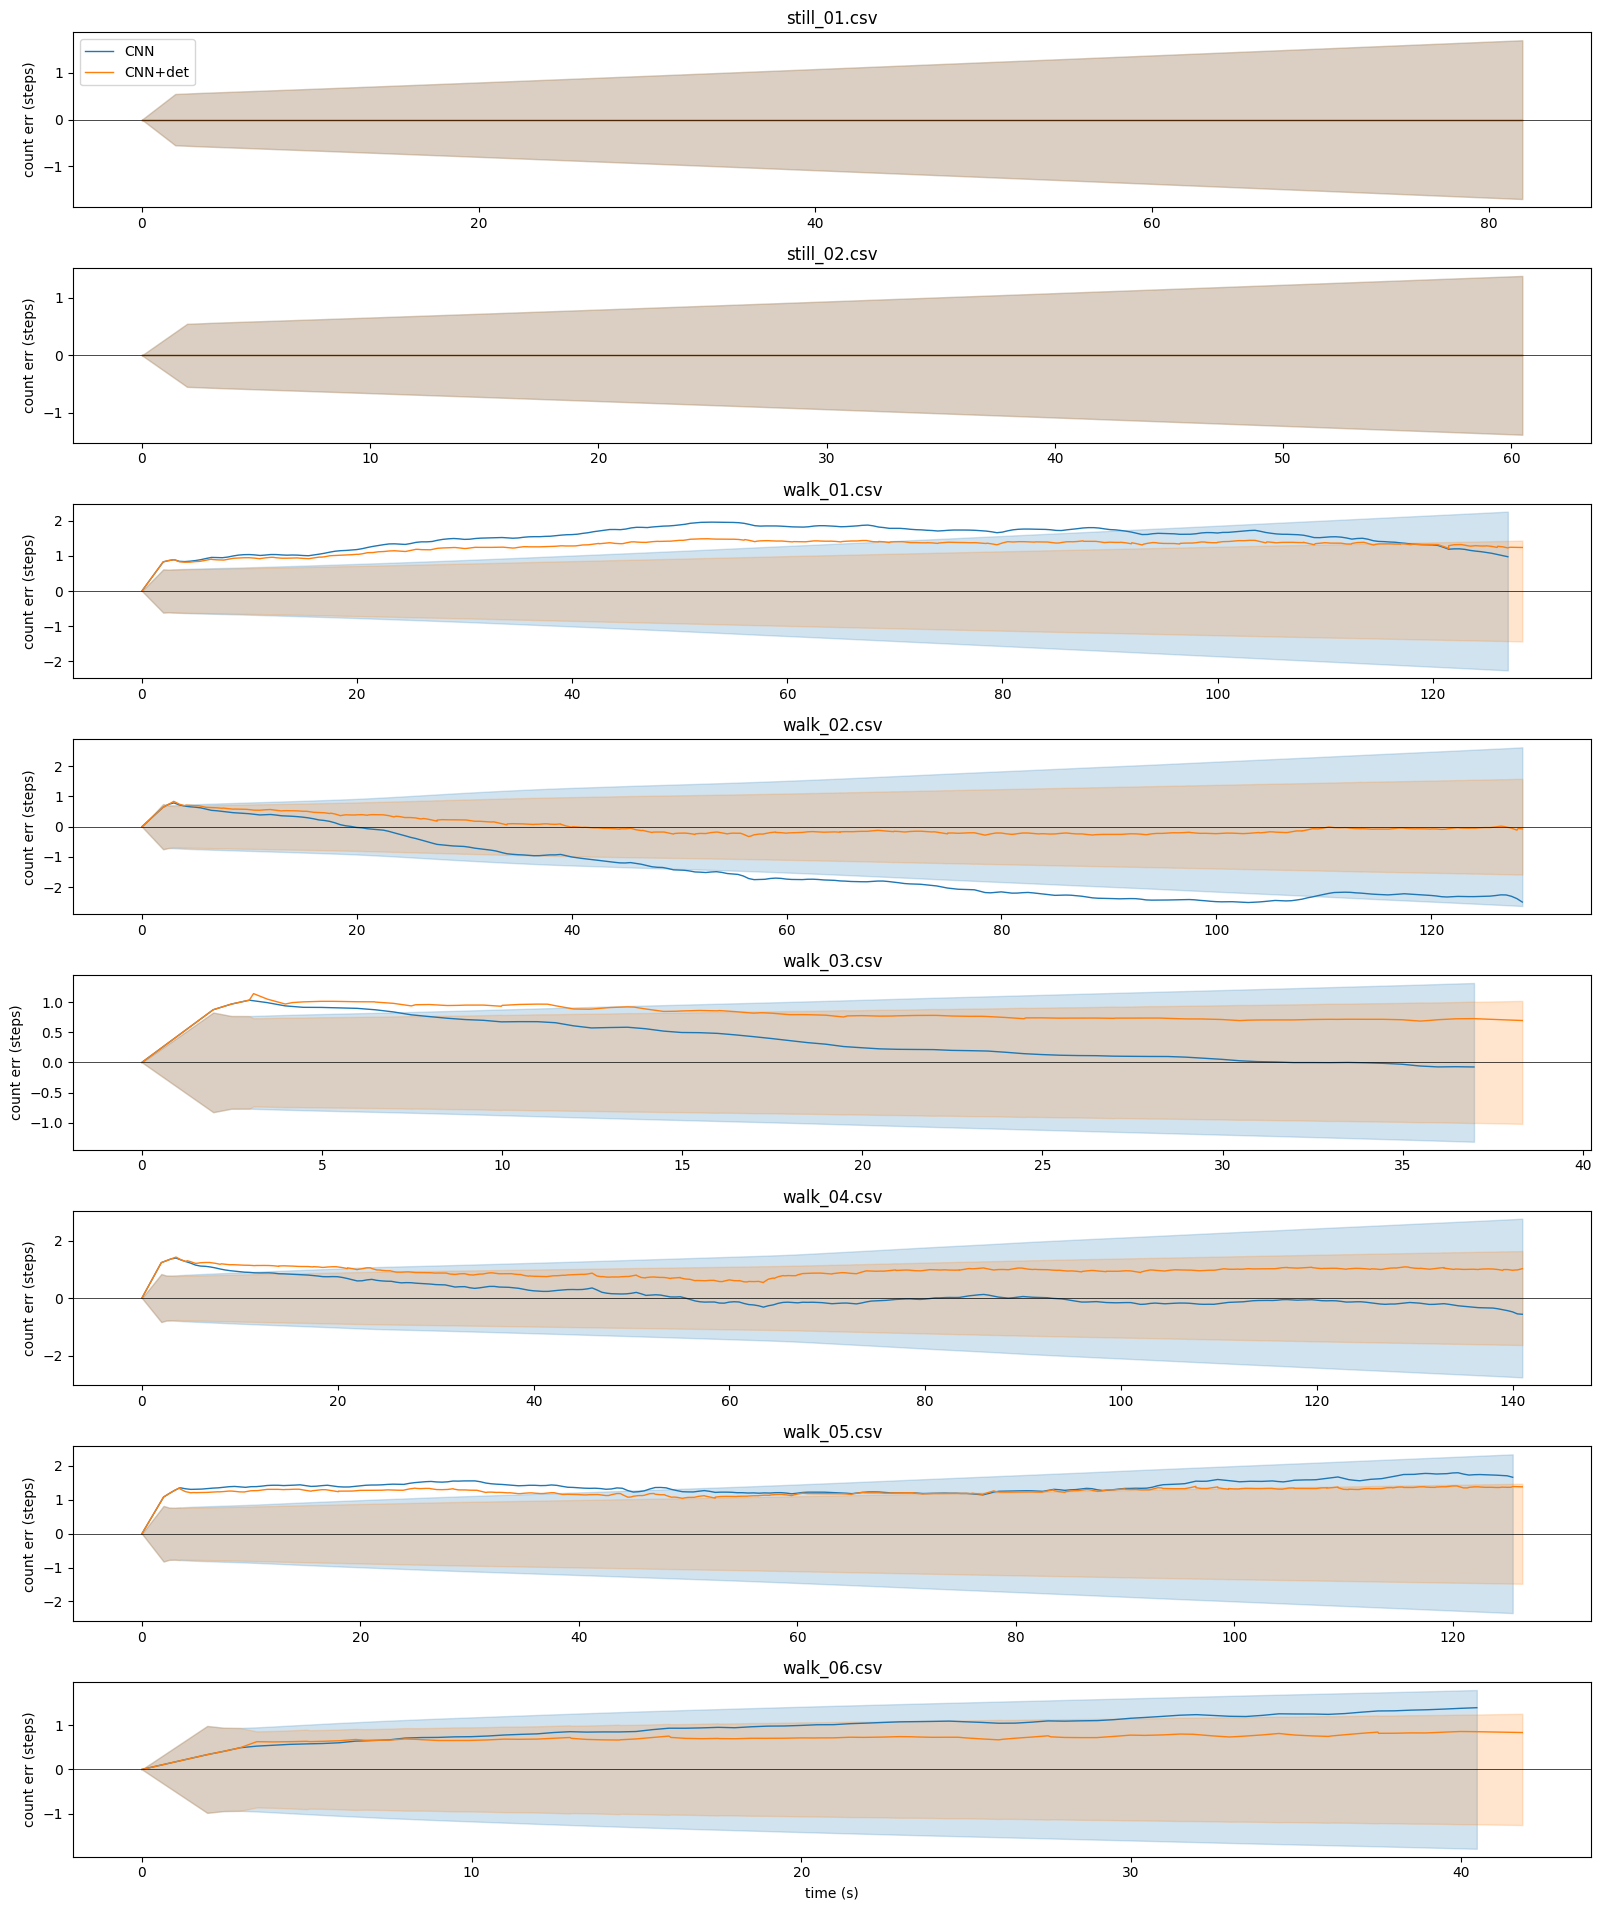

In [ ]:
fig, axs = plt.subplots(len(recs), 1, figsize=(16, 2.4 * len(recs)))
for ax, (f, (s, *_)) in zip(axs, recs.items()):
    knots = phase_knots(s)
    for i, m in enumerate(MODES):
        t, n, sig = runs[f, m]
        ax.plot(t, n - 2 * phase(t, knots), color=f"C{i}", lw=1, label=m)
        ax.fill_between(t, -sig, sig, color=f"C{i}", alpha=0.2)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(f)
    ax.set_ylabel("count err (steps)")
axs[0].legend(loc="upper left")
axs[-1].set_xlabel("time (s)")
fig.tight_layout()